# Climate change and time-dependent warming for a simple Energy Balance Model

## Motivation and Goals

This project was completed originally as part of a school submission. I have since updated the project to remove any unnecessary boilerplate or assignment related information. The general background for this project can be found here: [Zero Dimensional EBM assignment](https://brian-rose.github.io/ClimateLaboratoryBook/courseware/assignment-zero-dim-ebm/). More information is given in the README file. 

The goal of this project is to simulate a simple climate change model. Starting first with a system of simple differential equations, we can create a time-stepping model and progressively increase the complexity trending towards an increasingly accurate model of climate change over a period of time

### The equation of the Energy Balance Model

We first define a simple Energy Balance Model which will give us the global mean surface temperature $T_s$: The equations for such a model are as follows:

$$ C  \frac{dT_s}{dt} = \text{ASR} - \text{OLR}$$

$$ \text{ASR} = (1-\alpha) Q $$

$$ \text{OLR} = \tau \sigma T_s^4$$

where we have the following:

- $C$ is a heat capacity for the atmosphere-ocean column
- $\alpha$ is the global mean planetary albedo
- $\sigma = 5.67 \times 10^{-8}$ W m⁻² K⁻⁴ is the Stefan-Boltzmann constant
- $\tau$ is our transmissivity parameter for the atmosphere.
- $Q$ is the global-mean incoming solar radiation, or *insolation*.
- $\text{OLR}$ is the outgoing long-wave radiation
- $\text{ASR}$ is the absorbed shortwave radiation

### Making a first simulation

The first simulation is very simple and will obey the following constraints and parameters:

- $\tau$ decreases to 0.57 and $\alpha$ increases to 0.32. 
- A heat capacity of $C = 4\times10^8$ J m⁻² K⁻¹ and $C = 8\times10^8$ J m⁻² K⁻¹ (representing 200 meters of water). 
- The simulation timesteps for 50 years

In [1]:
%matplotlib inline  
import numpy as np
import matplotlib.pyplot as plt

# Define Constants
sigma = 5.67E-8  # S-B constant
Tsobserved = 288.  # global average surface temperature
Q = 341.3  # the insolation

# Other Values
Freflected = 101.9  #  reflected shortwave flux in W/m2
alpha = Freflected / Q # The albedo
tau = 0.57
dt = 60. * 60. * 24. * 365.   # one year expressed in seconds


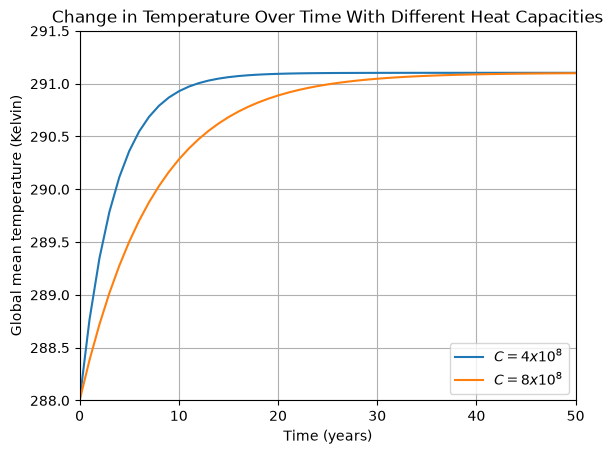

In [2]:
numsteps = 50

def ASR(Q=Q, alpha=alpha):
    return (1-alpha)*Q

def OLR(T, tau=tau):
    return tau * sigma * T**4

def step_forward(T, C):
    return T + dt / C * ( ASR(alpha=0.32) - OLR(T, tau=0.57) )

# Reusable function to get data and plot it
def make_data(numsteps, C, label):
    for n in range(numsteps):
        Years[n+1] = n+1
        Tsteps[n+1] = step_forward(Tsteps[n], C)
    plt.plot(Years, Tsteps, label=label)

# Create Arrays
Tsteps = np.zeros(numsteps+1)
Years = np.zeros(numsteps+1)
Tsteps[0] = 288. 

make_data(numsteps, 4e8, r"$C = 4 x 10^8$")
make_data(numsteps, 8e8, r"$C = 8 x 10^8$" )

# Display
plt.title("Change in Temperature Over Time With Different Heat Capacities")
plt.xlabel("Time (years)")
plt.ylabel("Global mean temperature (Kelvin)")
plt.xlim(0, 50)
plt.ylim(288, 291.5)
plt.grid(True)
plt.legend()
plt.show()

### An analysis of the role of heat capacity on climate change

1. In general, the global mean temperature does not increase linearly, but follows some kind of inverse exponential curve over time.
2. As the heat capacity increases, the increase of the global mean temperature increases *more slowly*, and the inverse exponential curve becomes more linear.

This makes sense physically, because a higher heat capacity means that more energy is required to change the temperature of the planet. So a higher heat capacity means that the planet will warm up more slowly. And just like we found in part (a), the equilibrium temperature is the same as we change heat capacities.

Because I made the time stepping and plotting a reusable function, I decided to keep increasing the values in increments of multiples of 4, to see if the trend continues

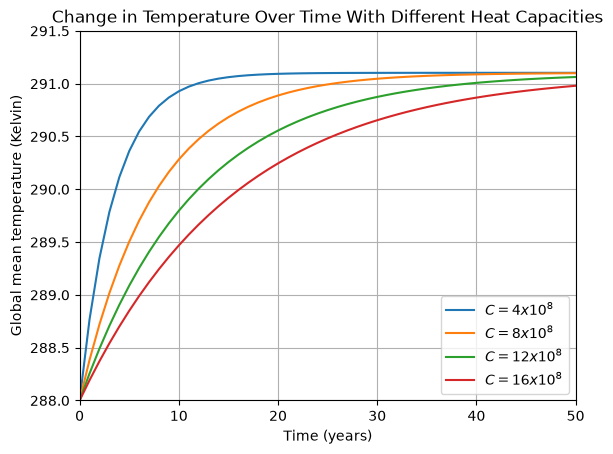

In [3]:
numsteps = 50

make_data(numsteps, 4e8, r"$C = 4 x 10^8$")
make_data(numsteps, 8e8, r"$C = 8 x 10^8$" )
make_data(numsteps, 12e8, r"$C = 12 x 10^8$")
make_data(numsteps, 16e8, r"$C = 16 x 10^8$" )

# Display
plt.title("Change in Temperature Over Time With Different Heat Capacities")
plt.xlabel("Time (years)")
plt.ylabel("Global mean temperature (Kelvin)")
# plt.text(1,1,'This text starts at point (1, 1)')
plt.xlim(0, 50)
plt.ylim(288, 291.5)
plt.grid(True)
plt.legend()
plt.show()


As expected, the trend continues. 

## Introducing albedo feedback

### Updating the simulation

Our first simulation is fine, but much too simple compared to some of the more complex models we could be using. We will now introduce some complexity into the model by making the planetary albedo a function of temperature. The reason for doing this is that a warmer planet has less ice and snow, which means the planet reflects less incoming radiation. This begins the creation of a simple feedback model which is already a big improvement over our first simple simulation

### The albedo formula

We will represent the ice-albedo feedback through the following simple formula:

$$ \alpha(T) = \left\{ \begin{array}{ccc}
\alpha_i &   & T \le T_i \\
\alpha_o + (\alpha_i-\alpha_o) \frac{(T-T_o)^2}{(T_i-T_o)^2} &   & T_i < T < T_o \\
\alpha_o &   & T \ge T_o \end{array} \right\}$$

with the following parameter values:

- $\alpha_o = 0.289$ is the albedo of a warm, ice-free planet
- $\alpha_i = 0.7$ is the albedo of a very cold, completely ice-covered planet
- $T_o = 293$ K is the threshold temperature above which we assume the planet is ice-free
- $T_i = 260$ K is the threshold temperature below which we assume the planet is completely ice covered. 

For intermediate temperature, this formula gives a smooth variation in albedo with global mean temperature. It is tuned to reproduce the observed albedo $\alpha = 0.299$ for $T = 288$ K. 

We will use this function to calculate the albedo versus a range of temperatures, and then display this on a graph. 

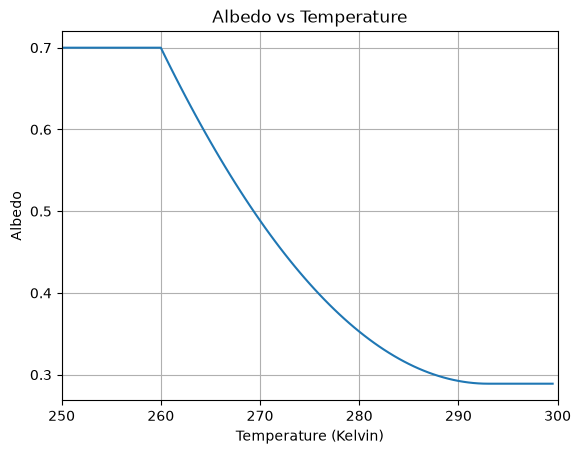

In [4]:
# This is just the given function for albedo written in code
def albedo_function(T):
    alpha_o = 0.289
    alpha_i = 0.7
    T_o = 293 # In Kelvin
    T_i = 260 # In Kelvin
    
    if (T <= T_i):
        return alpha_i
    elif (T >= T_o):
        return alpha_o
    elif ((T_i < T) and (T < T_o)):
        return ( alpha_o + ( (alpha_i - alpha_o) * ( (T-T_o)**2 / (T_i-T_o)**2) ) )

# Temperature starts at 250 to graphically show the bounds of the function for a given input T
temp = 250
numsteps = 100

# Make arrays
Temperatures = np.zeros(numsteps)
Albedo = np.zeros(numsteps)

# Iterate through arrays
for i in range(numsteps):
    Temperatures[i] = temp
    Albedo[i] = albedo_function(temp)
    temp = temp + 0.5

# Plot and display
plt.plot(Temperatures, Albedo)
plt.title(r"Albedo vs Temperature")    
plt.grid(True)
plt.xlim(250, 300)
plt.xlabel("Temperature (Kelvin)")
plt.ylabel("Albedo")
plt.show()

For this graph, I tried to find a good balance between the number of steps used and the temperature increments. The behavior here is interesting. First of all, it seems unphysical that the graph would begin decreasing sharply at $T = 260 K$ (The point is undifferentiable, and in physics we would typically assume smoothness everywhere, so the model is probably too simplistic here).

Besides this, the implications this has for what we can expect from climate change don't seem to be in our favor. It would be nicer if the graph decreased more gradually and linearly, giving us a much more controlled descent. We instead see the albedo drop off sharply and suddenly as temperature increases, and the descent only slows down once the temperature gets much hotter 

### Using this new model

Now we will use this new albedo model to do some new time-stepping. We will suppose from before that the transmissivity decreases from 0.611 to 0.57, but that the albedo is no longer a fixed number and instead varies according to our new function. Using this, we will calculate the new equilibrium temperature. 

Final temperature for Constant albedo: 293.370578925302
Final temperature for Changing albedo: 294.3655510215479


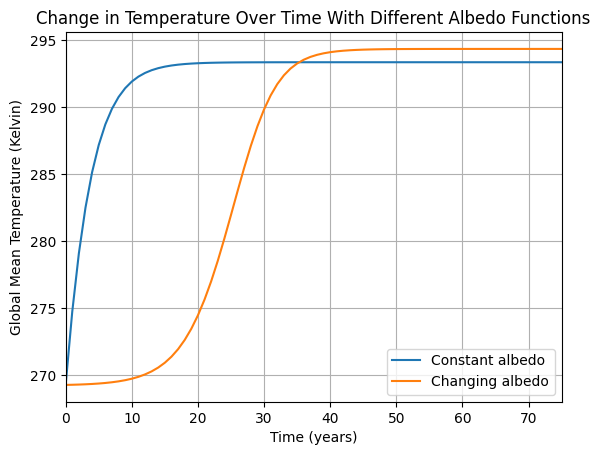

In [6]:
# Reset old values
numsteps = 75
C = 4e8

def ASR(alpha=alpha):
    return (1-alpha)*Q

def OLR(T, tau=tau):
    return tau * sigma * T**4

# Mostly the same code as before, but here we add a condition to determine if we should use the function or not
# to compare graphs. If yes, we set alpha equal to the output of the albedo function
def step_forward(T, albedo, use_function):
    if use_function == False:
        return T + dt / C * ( ASR(alpha=alpha) - OLR(T, tau=0.57) )
    if use_function == True:
        return T + dt / C * ( ASR(alpha=albedo) - OLR(T, tau=0.57) )
        
def make_data(use_function, label):
    Tsteps[0] = 269.25 # Define initial Temperature
    for n in range(75):
        albedo = albedo_function(Tsteps[n])
        Years[n+1] = n+1
        Tsteps[n+1] = step_forward(Tsteps[n], albedo, use_function)
    plt.plot(Years, Tsteps, label=label)
    print(f"Final temperature for {label}:", Tsteps[numsteps])

# Create Arrays
Tsteps = np.zeros(numsteps+1)
Years = np.zeros(numsteps+1)

make_data(False, "Constant albedo") # The original graph, no change
make_data(True, "Changing albedo") # Now decreasing


# Display
plt.title("Change in Temperature Over Time With Different Albedo Functions")
plt.xlabel("Time (years)")
plt.ylabel("Global Mean Temperature (Kelvin)")
plt.xlim(0, 75)
plt.grid(True)
plt.legend()
plt.show()

#### Analysis

We can see from the final temperature from each model that letting the albedo vary according to the function does make a difference in the equilibrium temperature, and that the difference is by about 1 K. This may not seem like a lot, but in terms of surface warming it is not insignificant. I would assume the reason this happens is because as the albedo drops near the end of the simulation, the temperature will increase more. 

The main thing to take away from this is that when albedo is treated as a dynamic value that feedbacks into the warming process, warming occurs more gradually at first before it follows the trend that we observe in the graphs before. However, this trend is only noticeable at much lower temperatures than the current global mean temperature. This makes sense physically and is exactly what we would expect: A higher albedo means slower warming, as more incoming radiation is reflected. (The intuitive way to think about this is in terms of snow cover. The more snow there is on the planet, the slower warming will occur. Once snow starts to melt, the planet will reflect less radiation and heat up more quickly as its temperature increases).

What's useful about this is that when albedo is factored into the model, it affects warming on much larger timescales. This gives us a nice model for the way that the planet exists, enters, and remains in ice ages, to give the simplest and most readily useful example. 

As a caveat, I'm still not super confident that a temperature of less than 271 K to start with is even realistic or makes sense physically. I looked up temperatures during the last ice age and they were only 6 degrees colder than our current global mean temperature. So something here probably needs some adjusting.

## Strong radiative forcing

Now we will introduce a strong negative radiative forcing. We will do this in two different ways:

1. First, we will do it by decreasing the incoming solar radiation $Q$
2. Second, we will do it by reducing greenhouse gases, which we will represent as an increase in the transmissivity $\tau$

#### Modifying the insolation 

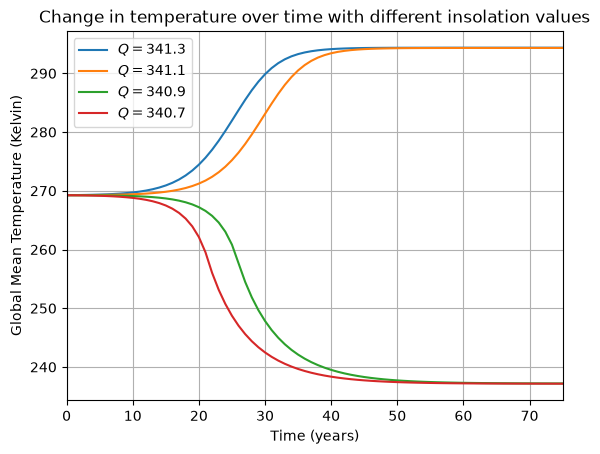

In [5]:
# Q = 341.3  # The original insolation

numsteps = 75
C = 4e8

def ASR(Q, alpha=alpha):
    return (1-alpha)*Q

def OLR(T, tau=tau):
    return tau * sigma * T**4

def step_forward(T, albedo, Q):
    return T + dt / C * ( ASR(Q, alpha=albedo) - OLR(T, tau=0.57) )
        
def make_data(Q, label):
    Tsteps[0] = 269.25 # Define initial Temperature
    for n in range(75):
        albedo = albedo_function(Tsteps[n])
        Years[n+1] = n+1
        Tsteps[n+1] = step_forward(Tsteps[n], albedo, Q)
    plt.plot(Years, Tsteps, label=label)

# Create Arrays
Tsteps = np.zeros(numsteps+1)
Years = np.zeros(numsteps+1)

make_data(341.3, r"$Q = 341.3$") # The original graph, no change
make_data(341.1, r"$Q = 341.1$") # Now decreasing
make_data(340.9, r"$Q = 340.9$")
make_data(340.7, r"$Q = 340.7$")

# Display
plt.title("Change in temperature over time with different insolation values")
plt.xlabel("Time (years)")
plt.ylabel("Global Mean Temperature (Kelvin)")
plt.xlim(0, 75)
plt.grid(True)
plt.legend()
plt.show()

#### Thoughts on Decreasing $Q$

At first I thought I did something wrong, but looking at the y axis, we see that the temperature is still starting from the same point. This means that subtly decreasing the insolation actually causes the planet to cool. Therefore, in the giant configuration space of the model, the point that the insolation value we've been using lies at is unstable - slightly perturbing it causes a big difference in the outcome of the global mean temperature over 50 years, at least according to our model and the way it has been run.

Its also important to think about if this actually makes sense physically. Insolation is the global mean incoming solar radiation, and as per the equation above, we have 

$$ \text{ASR} = (1-\alpha) Q $$

From this equation, we can see that decreasing $Q$ will decrease the ASR. Then from the main equation, after solving for $\frac{dT_s}{dt}$ we have

$$ \frac{dT_s}{dt} = (\text{ASR} - \text{OLR})/C$$

From our graphs, we see that the rate of change of the temperature goes from increasing to decreasing as insolation decreases. This means that the derivative must be changing from a positive value to a negative value as the ASR decreases. And the only way for the derivative to become negative is if the OLR becomes larger than the ASR. So this makes sense mathematically. Physically, whats happening is that as the insolation drops, the radiation leaving the planet becomes larger than the radiation being absorbed by the planet, and this causes the planet to cool over time. 

#### Further developments

Before moving on to changing the transmitivitty, I'm assuming that between the values of $Q = 341.3 $ and $Q = 340.7$ there is an extremely quick interpolation between the two graphs that we can't see, and I want to see how this works. Because I made the time-stepping and plotting a reusable function, I decided to iterate through it and increase the insolation by a small fraction of the increment. I did this first for increments of i/50, then i/100, and then i/1000 (only the i/1000 is shown). I was really expecting to see a point at which the graph becomes flat (its derivative is 0) and then sweeps down, but I never got this. Instead, all that happened was that the point at which an increase or decrease occurred became more and more delayed. The effect is really clear when comparing it to the graph above.

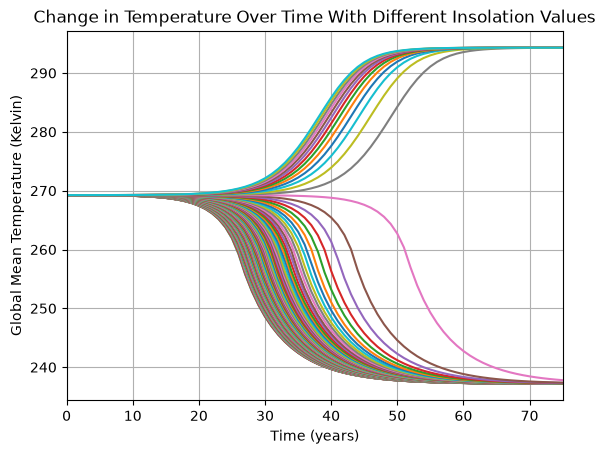

In [6]:
# Q = 341.3  # The original insolation

numsteps = 75
C = 4e8

def ASR(Q, alpha=alpha):
    return (1-alpha)*Q

def OLR(T, tau=tau):
    return tau * sigma * T**4

def step_forward(T, albedo, Q):
    return T + dt / C * ( ASR(Q, alpha=albedo) - OLR(T, tau=0.57) )
        
def make_data(Q):
    Tsteps[0] = 269.25 # Define initial Temperature
    for n in range(75):
        albedo = albedo_function(Tsteps[n])
        Years[n+1] = n+1
        Tsteps[n+1] = step_forward(Tsteps[n], albedo, Q)
    plt.plot(Years, Tsteps)

# Create Arrays
Tsteps = np.zeros(numsteps+1)
Years = np.zeros(numsteps+1)

for i in range (100):
    make_data((340.91 + i/1000)) # The original graph, no change

# Display
plt.title("Change in Temperature Over Time With Different Insolation Values")
plt.xlabel("Time (years)")
plt.ylabel("Global Mean Temperature (Kelvin)")
plt.xlim(0, 75)
plt.grid(True)
plt.show()

#### Increasing transmitivitty

Now we will try to increase transmitivitty $\tau$ while returning $Q$ to its original constant value

From the equation for OLR:

$$ \text{OLR} = \tau \sigma T_s^4$$

We should observe a similar, if not exactly the same trend, by increasing transmitivitty. The reason is that increasing $\tau$ should increase the OLR, causing it to become higher than the ASR, which should cause the graph to invert in the same way as before.

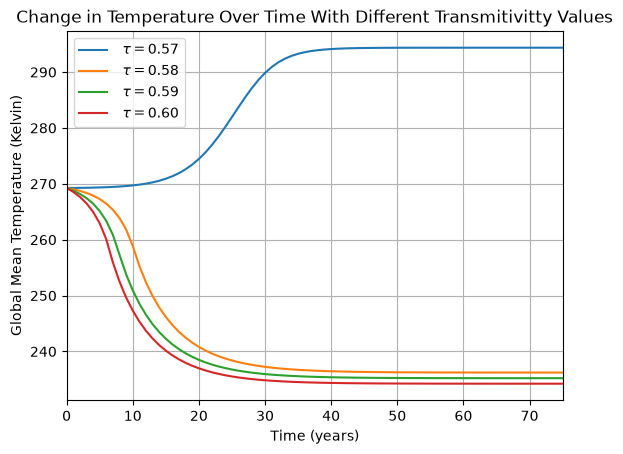

In [7]:
# We will use basically the same exact code but just change the input to our be tau instead of Q

Q = 341.3  # The insolation
# tau = 0.57 Original transmitivitty value

numsteps = 75
C = 4e8

def ASR(Q, alpha=alpha):
    return (1-alpha)*Q

def OLR(T, tau=tau):
    return tau * sigma * T**4

def step_forward(T, albedo, tau):
    return T + dt / C * ( ASR(Q, alpha=albedo) - OLR(T, tau=tau) )
        
def make_data(tau, label):
    Tsteps[0] = 269.25 # Define initial Temperature
    for n in range(75):
        albedo = albedo_function(Tsteps[n])
        Years[n+1] = n+1
        Tsteps[n+1] = step_forward(Tsteps[n], albedo, tau)
    plt.plot(Years, Tsteps, label=label)

# Create Arrays
Tsteps = np.zeros(numsteps+1)
Years = np.zeros(numsteps+1)

make_data(0.57, r" $\tau = 0.57$") # The original graph, no change
make_data(0.58, r" $\tau = 0.58$") # Now decreasing
make_data(0.59, r" $\tau = 0.59$")
make_data(0.60, r" $\tau = 0.60$")

# Display
plt.title("Change in Temperature Over Time With Different Transmitivitty Values")
plt.xlabel("Time (years)")
plt.ylabel("Global Mean Temperature (Kelvin)")
plt.xlim(0, 75)
plt.grid(True)
plt.legend()
plt.show()

#### Thoughts on increasing $\tau$ 

From these graphs, we observe basically the same thing, which is expected. There are some differences though:
1. The model actually seems even more sensitive to $\tau$ being changed than to $Q$ being changed. Why? Probably because in our equation $$ \text{OLR} = \tau \sigma T_s^4$$
   $\tau$ is a multiple of $T_s^4$ which means that changing it will change the OLR much more, and therefore change the difference more
2. Unlike the equilibrium reached when we perturb $Q$, perturbing $\tau$ causes different equilibrium temperatures after cooling/warming

## Conclusion

The main takeaway from the project is that slight differences in models can produce drastically different outcomes when doing time stepping. My own mental model tells me this is the case because when you are modeling without using a computer, your assumptions don't tend to give weird results because you can't extend them far enough. When you start to leverage compute to work with models, you quickly realize that small changes in assumptions produce drastically different outcomes, and these can in turn result in drastically different conclusions. (This really matters for something like climate science because it informs how we think about climate change, and all of the policy decisions and public awareness that comes out of that.)

Besides this, the actual results of the model are mostly expected using physical reasoning. The one thing that really surprised me was the effect that changing both the insolation and transmitivitty even by just a tiny bit had on the change in temperature over time. Its possible that if I had looked at the equations more deeply before starting the project this is something I could have expected, but it also kind of demonstrates the point of modeling if its taken to be an extension of experimentation - in some sense you are supposed to be surprised, and then figure out what happened later and if the math explains it or not. 